<a href="https://colab.research.google.com/github/davidsonclem/senai-quantum/blob/Master/14-visao-mercado-avancado/hands_on/atv/otimizacao_geo2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pós-Graduação em Computação Quântica — SENAI/CIMATEC 2026**
## **Disciplina:** Visão de Mercado em Tecnologias Quânticas
### **Grupo:** Davidson Clem, Joao Filipe Muchanga, Jose Hidalgo Suarez,
---
## **Hands On**
- ✅ Adicionar ao notebook Otimizacao_geo1.ipynb os canais de erro Bit-flip e Phase-flip, com taxas de 5% e 10%.
- ✅ Comparar os dois programas (Otimizacao_geo1.ipynb e Otimizacao_geo2.ipynb) com um modelo clássico, avaliando taxas de erro e convergência, nos casos com e sem ruído.

# Referência clássica: inversão geofísica com e sem ruído nos dados

Adaptação de `Otimizacao_geo2.ipynb` para comparar com o primeiro programa.
O modelo foi igualado ao de geo1: espessuras 400/350/450 m e velocidades
1800/2400/3000 m/s. O algoritmo de annealing simulado continua sendo clássico.

Este notebook requer apenas NumPy, SciPy, pandas, Matplotlib, dimod e
dwave-samplers; não depende de Qiskit. Usa as mesmas seeds e realizações
de ruído nos dados do experimento complementar de geo1.

Bit-flip/phase-flip são canais quânticos de portas e **não se aplicam** ao
annealing clássico. A comparação principal os confronta com esta referência.
O caso com ruído deste notebook refere-se exclusivamente aos tempos de trânsito.


In [ ]:
# %pip install dimod==0.12.22 dwave-samplers==1.8.0 numpy scipy pandas matplotlib

In [ ]:
import time, json, itertools, platform, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import dimod
from dwave.samplers import SimulatedAnnealingSampler

# Modelo comum aos dois programas: dados do Otimizacao_geo1 original.
H_TRUE = np.array([400., 350., 450.])
V_TRUE = np.array([1800., 2400., 3000.])
OFFSETS = np.array([600., 900., 1200.])
R_BITS, N_ITER, QAOA_P = 3, 8, 3
L_INIT = 3e-4
S_INIT = np.full(3, 1/2400.)
SEEDS = [11, 22, 33]
SHOTS_OBJECTIVE, SHOTS_FINAL = 128, 4096
MAXITER, RESTARTS = 45, 2
SA_READS, SA_SWEEPS = 100, 500
SCENARIOS = [('Sem ruido', None, 0.), ('Bit-flip 5%', 'X', .05),
             ('Bit-flip 10%', 'X', .10), ('Phase-flip 5%', 'Z', .05),
             ('Phase-flip 10%', 'Z', .10)]
DATA_NOISE_LEVELS = [0., .05, .10]

def build_M(h, offsets):
    H = np.cumsum(h)
    M = np.zeros((len(h), len(h)))
    for i in range(len(h)):
        theta = np.arctan((offsets[i]/2)/H[i])
        M[i, :i+1] = 2*h[:i+1]/np.cos(theta)
    return M

M = build_M(H_TRUE, OFFSETS)
T_TRUE = M @ (1/V_TRUE)
N_QUBITS = len(V_TRUE)*R_BITS
# O bit q_j corresponde ao qubit j (little-endian).
ALL_Q = ((np.arange(2**N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1).astype(int)

def expand_binary(M, R):
    return np.column_stack([M[:, i]*2.**(-r)
                            for i in range(M.shape[1]) for r in range(R)])

def qubo_from_ls(A, b):
    G = A.T @ A
    Q = np.triu(2*G, 1)
    np.fill_diagonal(Q, np.diag(G)-2*A.T@b)
    return Q, float(b@b)

def q_to_x(q, n_real=3, R=R_BITS):
    return np.asarray(q).reshape(n_real, R) @ (2.**(-np.arange(R)))

def make_problem(s, L, t):
    A = expand_binary(M, R_BITS)
    b = (t + L*(M@np.ones(3)) - M@s)/L
    Q, off = qubo_from_ls(A, b)
    # Norma direta evita cancelamento entre grandes coeficientes no custo QUBO.
    energies = np.sum((ALL_Q@A.T-b)**2, axis=1)
    best = int(np.argmin(energies))
    return Q, off, energies, best

def qubo_to_ising(Q, off):
    n = len(Q)
    h = -np.diag(Q)/2
    J = np.triu(Q, 1)/4
    h -= J.sum(axis=0)+J.sum(axis=1)
    const = off + np.trace(Q)/2 + J.sum()
    return h, J, const

def record(method, experiment, scenario, rate, seed, it, s, L, t, elapsed, **extra):
    v = 1/s
    row = dict(method=method, experiment=experiment, scenario=scenario, rate=rate,
               seed=seed, iteration=it, residual_s=float(np.linalg.norm(M@s-t)),
               error_max_pct=float(np.max(np.abs(v-V_TRUE)/V_TRUE)*100),
               error_mean_pct=float(np.mean(np.abs(v-V_TRUE)/V_TRUE)*100),
               seconds=elapsed, v1=float(v[0]), v2=float(v[1]), v3=float(v[2]), L=L)
    row.update(extra)
    return row

def solve_sa(Q, off, energies, seed):
    Qd = {(i,j): float(Q[i,j]) for i in range(len(Q)) for j in range(i,len(Q))}
    bqm = dimod.BinaryQuadraticModel.from_qubo(Qd, offset=off)
    samples = SimulatedAnnealingSampler().sample(
        bqm, num_reads=SA_READS, num_sweeps=SA_SWEEPS, seed=seed)
    probs = np.zeros(len(energies))
    for datum in samples.data(['sample','num_occurrences']):
        idx = sum(int(datum.sample[j])*(1<<j) for j in range(len(Q)))
        probs[idx] += datum.num_occurrences/SA_READS
    seen = np.flatnonzero(probs)
    idx = int(seen[np.argmin(energies[seen])])
    return idx, probs

def classical_run(t, experiment, scenario, rate, seed):
    s, L = S_INIT.copy(), L_INIT
    rows = []
    start = time.perf_counter()
    for it in range(1,N_ITER+1):
        Q, off, E, best = make_problem(s,L,t)
        idx, probs = solve_sa(Q,off,E,seed+it)
        s += L*(q_to_x(ALL_Q[idx])-1)
        rows.append(record('Annealing classico',experiment,scenario,rate,seed,it,
                           s,L,t,time.perf_counter()-start,
                           optimal_success=int(idx==best),
                           p_opt=float(probs[best]), mean_sample_cost_s2=float(L*L*(probs@E))))
        L *= .25
    direct_start = time.perf_counter()
    exact_s = np.linalg.solve(M,t)
    direct_seconds = time.perf_counter()-direct_start
    rows.append(record('Sistema linear',experiment,scenario,rate,seed,N_ITER,
                       exact_s,0,t,direct_seconds,optimal_success=1,p_opt=np.nan,
                       mean_sample_cost_s2=float(np.linalg.norm(M@exact_s-t)**2)))
    return rows

# Testes reais da formulacao sobre todas as configuracoes binarias.
def validate_mapping():
    Q,off,E,_ = make_problem(S_INIT,L_INIT,T_TRUE)
    alpha = np.max(np.abs(Q))
    h,J,c = qubo_to_ising(Q/alpha,off/alpha)
    z = 1-2*ALL_Q
    Ei = z@h + np.einsum('bi,ij,bj->b',z,J,z)+c
    Eq = np.einsum('bi,ij,bj->b',ALL_Q,Q,ALL_Q)+off
    assert np.max(np.abs(Eq-E)) < 1e-7
    assert np.max(np.abs(Ei-E/alpha)) < 1e-12
    assert np.allclose(np.linalg.solve(M,T_TRUE),1/V_TRUE)
    return {'estados_testados':len(E),'erro_QUBO_norma':float(np.max(np.abs(Eq-E))),
            'erro_Ising_normalizado':float(np.max(np.abs(Ei-E/alpha)))}

VALIDATION = validate_mapping()
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['numpy','scipy','dimod','dwave-samplers']}



In [ ]:
print(VERSIONS)
print(VALIDATION)

{'numpy': '2.3.5', 'scipy': '1.17.0', 'dimod': '0.12.22', 'dwave-samplers': '1.8.0'}
{'estados_testados': 512, 'erro_QUBO_norma': 2.852175384759903e-09, 'erro_Ising_normalizado': 4.440892098500626e-16}


In [ ]:
rows = []
for seed in SEEDS:
    rows += classical_run(T_TRUE, 'Dados', 'Sem ruido', 0., seed)
    for rate in [.05,.10]:
        rng = np.random.default_rng(seed+10000)
        t = T_TRUE*(1+rate*rng.normal(size=3))
        rows += classical_run(t, 'Dados', f'Dados gaussianos {rate:.0%}', rate, seed)
df_classico = pd.DataFrame(rows)
df_classico.to_csv('resultados_classico.csv', index=False)
display(df_classico[df_classico.iteration==N_ITER].groupby(['method','scenario']).agg(
    erro_max_medio_pct=('error_max_pct','mean'),
    desvio_erro_pct=('error_max_pct','std'),
    residuo_medio_s=('residual_s','mean')).round(7))


erro_max_medio_pct  ...  residuo_medio_s
method             scenario                                  ...                 
Annealing classico Dados gaussianos 10%           43.280892  ...         0.000002
                   Dados gaussianos 5%            20.088859  ...         0.000144
                   Sem ruido                       0.001099  ...         0.000003
Sistema linear     Dados gaussianos 10%           43.281427  ...         0.000000
                   Dados gaussianos 5%            20.130087  ...         0.000000
                   Sem ruido                       0.000000  ...         0.000000

[6 rows x 3 columns]

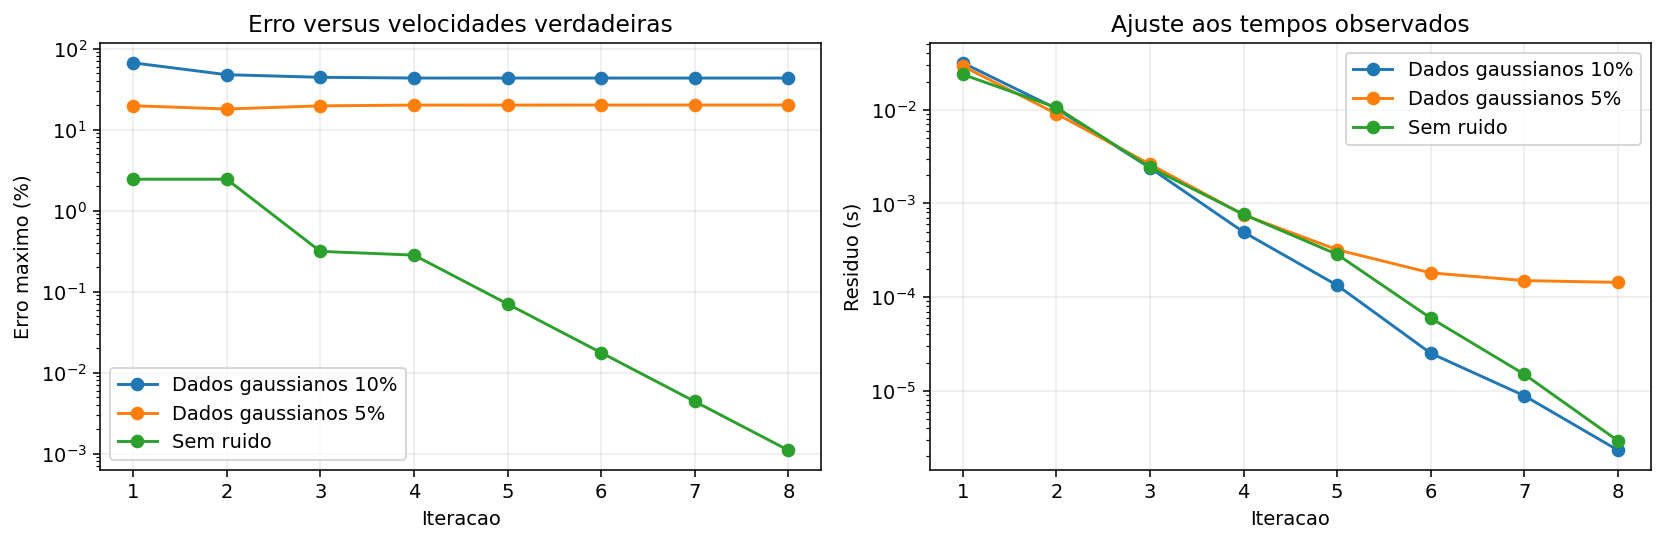

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
sa = df_classico[df_classico.method=='Annealing classico']
for scenario, group in sa.groupby('scenario'):
    for ax, metric in zip(axes,['error_max_pct','residual_s']):
        means = group.groupby('iteration')[metric].mean()
        ax.semilogy(means.index, np.maximum(means,1e-12), 'o-', label=scenario)
axes[0].set(title='Erro versus velocidades verdadeiras',ylabel='Erro maximo (%)')
axes[1].set(title='Ajuste aos tempos observados',ylabel='Residuo (s)')
for ax in axes: ax.set_xlabel('Iteracao'); ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); plt.show()


O sistema linear direto fornece uma referência contínua.
O annealing resolve uma aproximação discreta refinada em oito etapas.
Erro nos dados pode aumentar o erro do modelo mesmo que o resíduo diminua.
Os resultados não incluem regularização nem incerteza da geometria.
